In [2]:
import tensorflow as tf 
from tensorflow.keras import layers, Sequential
from sklearn import preprocessing , datasets , model_selection
import matplotlib.pyplot as pt  
import numpy as np 

In [3]:
digits =datasets.load_digits()

In [4]:
digits.keys()

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])

In [5]:
X= digits['data']
y = digits['target']

In [ ]:
X = X.reshape(-1,8,8,1).astype('float') / 16

In [7]:
X.shape

(1797, 8, 8, 1)

In [8]:
X_train, X_test , y_train , y_test =model_selection.train_test_split(X,y,test_size=0.1, random_state= 1)

In [9]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(1617, 8, 8, 1)
(1617,)
(180, 8, 8, 1)
(180,)


<div dir=rtl>
<p>
stride = 1: فیلتر هر بار یک پیکسل حرکت می‌کند، پس خروجی تقریباً هم‌اندازه ورودی می‌ماند و جزئیات بیشتری حفظ می‌شود.
</p>
<p>
stride = 2: فیلتر هر بار دو پیکسل می‌پرد، پس طول و عرض خروجی تقریباً نصف می‌شود.
</p>
<p>
stride = 4: مثل لایه اول AlexNet، فیلتر چهار پیکسل می‌پرد و خروجی خیلی کوچک‌تر می‌شود.
</p>

</div>

In [10]:
import Utility as util

In [11]:
# model = Sequential([
    
#     layers.Conv2D(32,(3),strides=4, activation='relu' , name="Conv1"),
#     layers.MaxPooling2D(2,strides=2),
    
#     layers.Conv2D(96,(3),strides=4, activation= 'relu' , name='Conv2'),
#     layers.MaxPooling2D(3,strides=2),
    
#     layers.Conv2D(384 , (3),padding='same', activation='relu'),
#     layers.Conv2D(384 , (3) ,padding='same' , activation='relu'),
#     layers.Conv2D(256 , (3) ,padding='same' , activation='relu'),
#     layers.MaxPooling2D( (3),strides=2), 
    
#     #flatten
#     layers.Flatten(),
#     layers.Dropout(0.1),
#     layers.Dense(4096,activation='relu'),
#     layers.Dropout(0.2),
#     layers.Dense(4096,activation='relu'),
#     layers.Dense(10,activation='softmax'),
# ])

In [12]:
# calc = (
#     util.ShapeCalculator(8)
#     .conv("Conv1", kernel=3, stride=1, filters=32)
#     .pool("Pool1", kernel=3)
#     .conv("Conv2", kernel=3, stride=1, filters=96)
#     .pool("Pool2", kernel=2, stride=1)
#     .conv("Conv3", kernel=3, stride=1, filters=384)
#     .conv("Conv4", kernel=3, stride=1, filters=384)
#     .conv("Conv5", kernel=3, stride=1, filters=256)
# )
# calc.run()
# # print("----" * 20)
# # calc.run(128)  # ورودی دلخواه

<div dir=rtl>
<p>
•	Conv1 دارای ۳۲ فیلتر است. هر فیلتر یک نقشه ویژگی (feature map) 8×8 می‌سازد، پس خروجی ۳۲ کانال دارد.
</p>
</div>

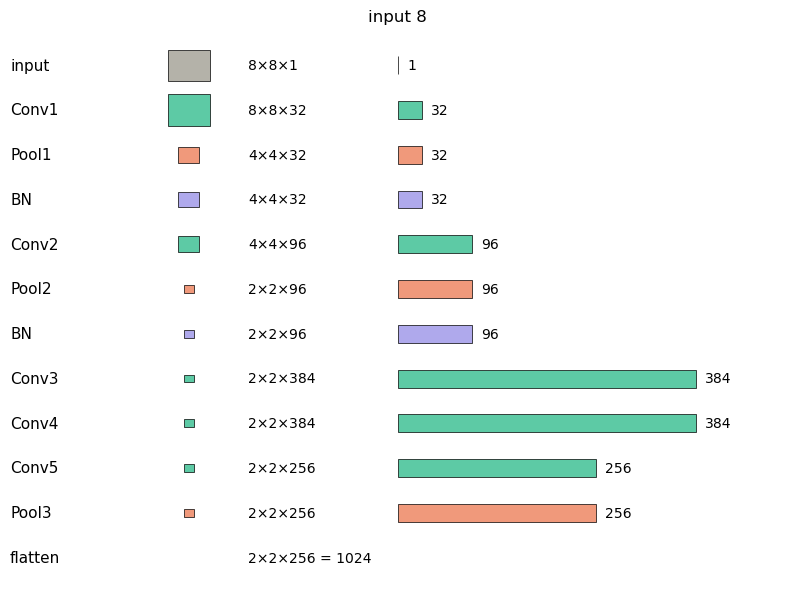

In [14]:
calc = (
    util.ShapeCalculator(8)
    .conv("Conv1", kernel=2, pad="same", filters=32)
    .pool("Pool1", kernel=2)
    .bn()
    .conv("Conv2", kernel=3, pad="same", filters=96)
    .pool("Pool2", kernel=2)
    .bn()
    .conv("Conv3", kernel=3, pad="same", filters=384)
    .conv("Conv4", kernel=3, pad="same", filters=384)
    .conv("Conv5", kernel=3, pad="same", filters=256)
    .pool("Pool3", kernel=1)
)
# calc.run()
calc.plot()

In [ ]:
# model = Sequential([
#      layers.Input(shape=(8, 8, 1)),
     
#     layers.Conv2D(32,(3),padding='same', activation='relu' , name="Conv1"),
#     layers.MaxPooling2D(2), # 8x8 -> 4x4
#     layers.BatchNormalization(),
    
#     layers.Conv2D(96,(3),padding='same', activation= 'relu' , name='Conv2'),
#     layers.MaxPooling2D(2),  # 4x4 -> 2x2
#     layers.BatchNormalization(),
    
#     layers.Conv2D(384 , (3),padding='same', activation='relu'),
#     layers.Conv2D(384 , (3) ,padding='same' , activation='relu'),
#     layers.Conv2D(256 , (3) ,padding='same' , activation='relu'),
#     layers.MaxPooling2D(2),   # 2x2 -> 1x1
    
#     #flatten
#     layers.Flatten(),
#     layers.Dropout(0.1),
#     layers.Dense(4096,activation='relu'),
#     layers.Dropout(0.2),
#     layers.Dense(4096,activation='relu'),
#     layers.Dense(10,activation='softmax'),
# ])

In [15]:
model = Sequential([
     layers.Input(shape=(8, 8, 1)),
     
    layers.Conv2D(32,(3,3),padding='same', activation='relu' , name="Conv1"),
    layers.MaxPooling2D(2), # 8x8 -> 4x4
    # layers.BatchNormalization(),
    
    layers.Conv2D(96,(3,3),padding='same', activation= 'relu' , name='Conv2'),
    layers.MaxPooling2D(2),  # 4x4 -> 2x2
    # layers.BatchNormalization(),
    
    layers.Conv2D(384 , (3,3),padding='same', activation='relu'),
    layers.Conv2D(384 , (3,3) ,padding='same' , activation='relu'),
    layers.Conv2D(256 , (3,3) ,padding='same' , activation='relu'),
    layers.MaxPooling2D(2),   # 2x2 -> 1x1
    
    #flatten
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(4096,activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(4096,activation='relu'),
    layers.Dense(10,activation='softmax'),
])

In [16]:
model.compile(optimizer='adam',loss = 'sparse_categorical_crossentropy' , metrics=['accuracy'])

In [17]:
history = model.fit(X_train, y_train, batch_size=32, epochs=50, validation_split=0.2 , verbose= 1)

Epoch 1/50
15/41 ━━━━━━━━━━━━━━━━━━━━ 4s 161ms/step - accuracy: 0.0957 - loss: 2.3051

KeyboardInterrupt: 

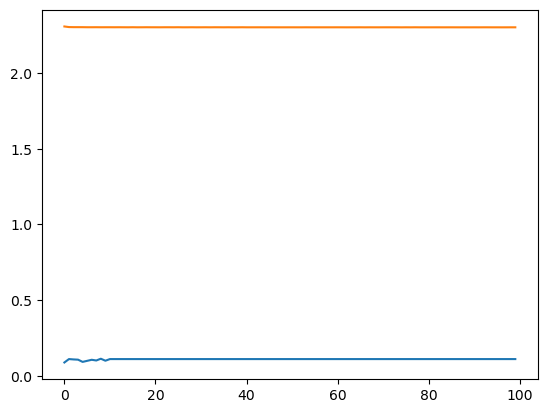

In [17]:
pt.plot(history.history['accuracy'])
pt.plot(history.history['loss'])

In [18]:
model.evaluate(X_test,y_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0611 - loss: 2.3100


[2.3100204467773438, 0.06111111119389534]